# <br>

<img src="logo_UNSAM.jpg" align="right" width="180" /> 

<br><br><br>

<h3 align="center">Análisis y Procesamiento de Señales</h3>

<h1 align="center"><b>TS8 - Filtrado No Lineal de Señales Biomédicas (ECG)</b></h1>
<h3 align="center">Olivia Weihmuller, Luz Romero Marchione y Paloma Ribnikar Diaz</h3>


## Objetivos

El objetivo principal de este trabajo semanal es implementar y analizar técnicas de procesamiento digital no lineales para corregir el movimiento de la línea de base de un registro electrocardiográfico (ECG), y desarrollar un método de detección de complejos QRS.

Para ello, se propone:

- Estimar y eliminar el movimiento de la línea de base mediante filtros de mediana aplicados en dos etapas.
- Implementar una estimación alternativa mediante interpolación con splines cúbicos, utilizando puntos de referencia de la región PQ.
- Comparar ambas estimaciones, evaluando su capacidad para corregir la línea de base y las posibles distorsiones introducidas en el ECG.
- Implementar un filtro adaptado a partir de un patrón QRS conocido y procesar su salida para facilitar la detección de los complejos.
- Evaluar el desempeño del detector mediante su comparación con las detecciones de referencia, calculando la sensibilidad y el valor predictivo positivo (VPP).

## Introducción

En el trabajo semanal anterior se estudió el diseño y la aplicación de filtros digitales lineales para mitigar las interferencias presentes en un registro electrocardiográfico (ECG). En esta práctica se incorporan técnicas de filtrado no lineal, interpolación y detección de eventos, con el objetivo de corregir el movimiento de la línea de base e identificar los complejos QRS.

### Estimación y corrección de la línea de base

La señal registrada puede representarse como $x[n]=s[n]+b[n]+r[n]$, donde $s[n]$ es el ECG de interés, $b[n]$ representa el movimiento de la línea de base y $r[n]$ las restantes interferencias. Para corregirla, se obtiene una estimación $\hat{b}[n]$ que se resta del registro original: $\hat{s}[n]=x[n]-\hat{b}[n]$.

**Filtrado de mediana**

El filtro de mediana es un sistema no lineal que reemplaza cada muestra por la mediana de los valores contenidos en una ventana temporal. Para una ventana impar de longitud $M$, se define:

$$
y[n]=\operatorname{mediana}\left\{x[n-k],\quad k=-\frac{M-1}{2},\ldots,\frac{M-1}{2}\right\}
$$

A diferencia del promedio móvil, presenta mayor robustez frente a valores extremos, lo que permite reducir la influencia de estructuras de gran amplitud y corta duración, como los complejos QRS, al estimar la línea de base. Sin embargo, por su naturaleza no lineal, puede introducir distorsiones en la morfología de la señal.

**Interpolación mediante splines cúbicos**

La interpolación mediante splines cúbicos consiste en construir una función continua a partir de polinomios de tercer grado definidos por tramos, que mantienen continuidad en sus primeras dos derivadas.

En esta práctica, se utiliza para estimar la línea de base a partir de puntos seleccionados en regiones aproximadamente isoeléctricas del ECG, próximas al intervalo PQ. La curva resultante proporciona una estimación suave de la perturbación, aunque su precisión depende de la correcta elección de los puntos de interpolación.

### Detección de complejos QRS mediante filtro adaptado

Un filtro adaptado (*matched filter*) permite identificar regiones de una señal que presentan semejanza con un patrón conocido. Su funcionamiento se basa en la correlación entre la señal y dicho patrón, que puede implementarse mediante una convolución con el patrón invertido temporalmente, $h[n]=p[L-1-n]$.

En este caso, se utiliza un patrón QRS para obtener respuestas de mayor magnitud en regiones con morfología similar. Para facilitar la comparación de las señales, se aplica una normalización:

$$
x_{\mathrm{norm}}[n]=\frac{x[n]-\mu_x}{\sigma_x}
$$

Donde $\mu_x$ y $\sigma_x$ representan la media y la desviación estándar, respectivamente.

### Procesamiento de la señal de detección

Para facilitar la identificación de los máximos se utiliza un **filtro de orden estadístico**, que selecciona un valor de cada ventana según su posición entre las muestras ordenadas.

Mientras que la mediana corresponde al percentil 50, un percentil elevado, como el 90, permite conservar valores próximos a los máximos de la ventana y rellenar pequeñas depresiones de la señal.

Posteriormente, se utiliza `scipy.signal.find_peaks()` para localizar los máximos, estableciendo restricciones como una separación temporal mínima y un umbral de amplitud.

### Evaluación del detector

El desempeño del detector se evalúa mediante una **matriz de confusión**, que permite clasificar las detecciones según su coincidencia con las referencias proporcionadas por la cátedra, considerando una tolerancia temporal determinada.

Se distinguen los verdaderos positivos (TP), correspondientes a QRS correctamente identificados; los falsos positivos (FP), que representan detecciones incorrectas; y los falsos negativos (FN), correspondientes a QRS no detectados.

A partir de estos valores se calculan dos indicadores:

- **Sensibilidad:** proporción de QRS reales correctamente detectados, $\mathrm{Sensibilidad}=\frac{TP}{TP+FN}\cdot100$.
- **Valor predictivo positivo (VPP):** proporción de detecciones que corresponden efectivamente a un QRS, $VPP=\frac{TP}{TP+FP}\cdot100$.

Estas métricas permiten evaluar la capacidad del método para detectar los complejos QRS y distinguirlos de otros eventos presentes en el ECG.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
import scipy.io as sio
from scipy.interpolate import CubicSpline

plt.close('all')

# Configuración de visualización
plt.style.use('default')

# Frecuencia de muestreo del registro
fs_ecg = 1000  # Hz

# Carga de datos del registro
mat_struct = sio.loadmat('ECG_TP4.mat')
ecg_one_leadruido = mat_struct['ecg_lead'].flatten()
qrs_detections_ref = mat_struct['qrs_detections'].flatten().astype(int)
qrs_pattern1 = mat_struct['qrs_pattern1'].flatten()

cant_muestras = len(ecg_one_leadruido)

print("Datos cargados correctamente:")
print(f" - Muestras totales de ECG: {cant_muestras:,} ({cant_muestras/fs_ecg:.1f} s)")
print(f" - Cantidad de latidos de referencia en el registro: {len(qrs_detections_ref)}")
print(f" - Longitud del patrón QRS (qrs_pattern1): {len(qrs_pattern1)} muestras")


Datos cargados correctamente:
 - Muestras totales de ECG: 1,129,116 (1129.1 s)
 - Cantidad de latidos de referencia en el registro: 1903
 - Longitud del patrón QRS (qrs_pattern1): 113 muestras


## Estimación de la línea de base mediante filtros de mediana

### ¿Por qué usamos dos etapas de mediana?
Para estimar la línea de base del ECG usamos dos filtros de mediana consecutivos:

$$\hat{b}[n] = \text{med}_{600}\Big(\text{med}_{200}(x[n])\Big)$$

Elegimos ventanas impares de 201 y 601 muestras (a 1000 Hz equivalen a 201 ms y 601 ms) para tener una muestra central bien definida:
- **Primera etapa (201 muestras):** Se encarga de atenuar los complejos QRS, que son variaciones rápidas y de corta duración.
- **Segunda etapa (601 muestras):** Se aplica sobre la salida anterior y, al ser una ventana más ancha, se encarga de eliminar estructuras más lentas como las ondas T y P.

De esta forma, la salida final `b_mediana` representa la estimación de la línea de base lenta. Después, la restamos del registro original para obtener el ECG corregido:

$$\hat{s}[n] = x[n] - \hat{b}[n]$$


Estimación de mediana calculada con éxito.


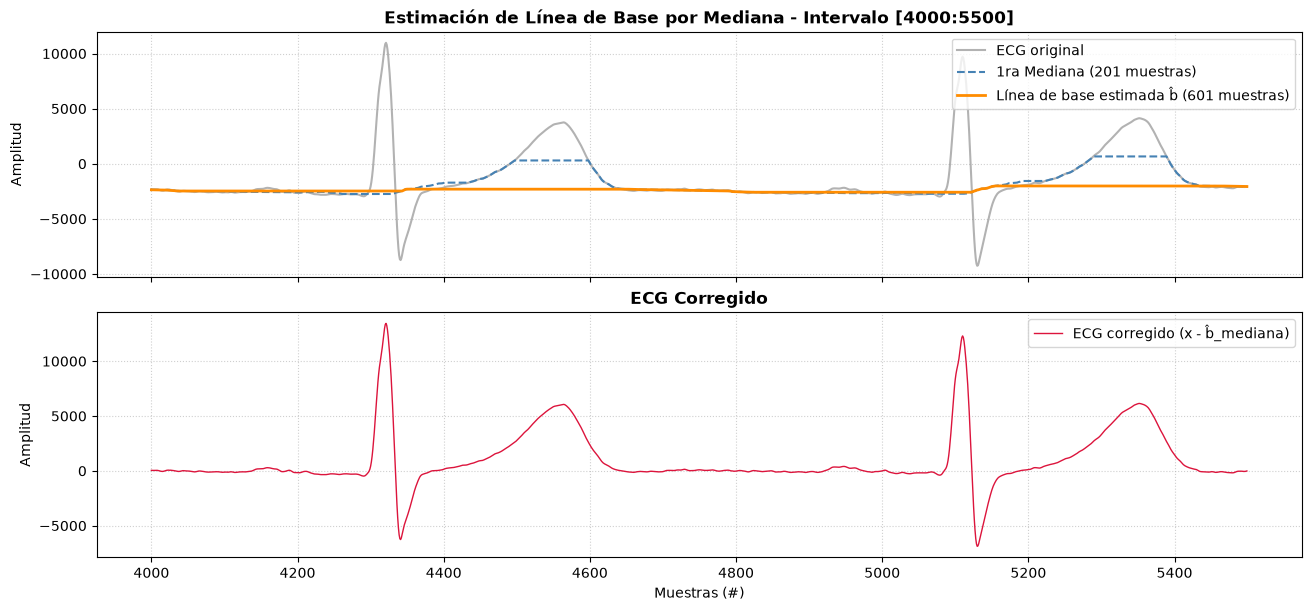

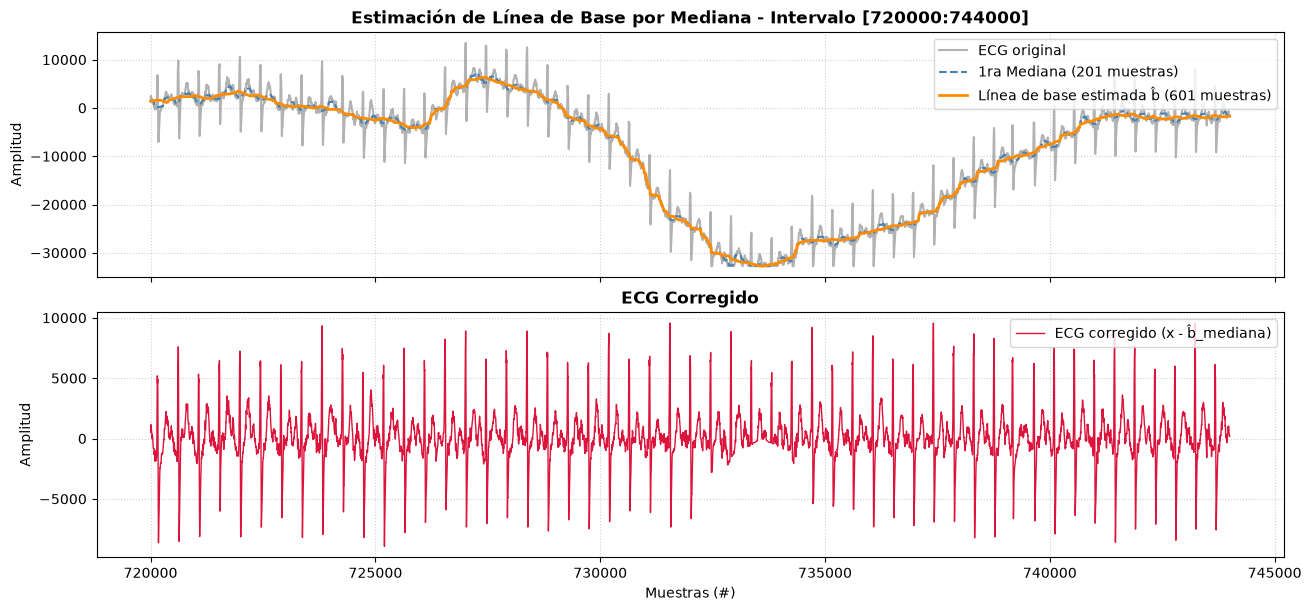

In [14]:
#%% ESTIMACIÓN DE LA LÍNEA DE BASE CON MEDIANA

# Primera etapa: ventana de 201 muestras (elimina QRS)
b_200 = sig.medfilt(ecg_one_leadruido, 201)

# Segunda etapa: ventana de 601 muestras sobre la salida anterior (elimina ondas T y P)
b_mediana = sig.medfilt(b_200, 601)

# Señal de ECG corregida por sustracción
ecg_mediana = ecg_one_leadruido - b_mediana

print("Estimación de mediana calculada con éxito.")

# Visualización de la estimación en dos regiones de interés
regs_mediana = ([4000, 5500], [720000, 744000])

for inicio, fin in regs_mediana:
    zoom_r = np.arange(inicio, fin)
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True, constrained_layout=True)
    
    # Estimación de la línea de base
    ax1.plot(zoom_r, ecg_one_leadruido[zoom_r], color='gray', alpha=0.6, label='ECG original')
    ax1.plot(zoom_r, b_200[zoom_r], color='steelblue', linestyle='--', label='1ra Mediana (201 muestras)')
    ax1.plot(zoom_r, b_mediana[zoom_r], color='darkorange', linewidth=2, label='Línea de base estimada b̂ (601 muestras)')
    ax1.set_title(f'Estimación de Línea de Base por Mediana - Intervalo [{inicio}:{fin}]', fontweight='bold')
    ax1.set_ylabel('Amplitud')
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='upper right')
    
    # ECG corregido
    ax2.plot(zoom_r, ecg_mediana[zoom_r], color='crimson', linewidth=1, label='ECG corregido (x - b̂_mediana)')
    ax2.set_title('ECG Corregido', fontweight='bold')
    ax2.set_xlabel('Muestras (#)')
    ax2.set_ylabel('Amplitud')
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend(loc='upper right')
    
    plt.show()


### Análisis de los resultados del filtrado de mediana

Al mirar los gráficos obtenidos podemos sacar las siguientes observaciones:

1. **Reducción de la línea de base:**
   Al restar `b_mediana`, el ECG queda bien centrado alrededor de cero. Esto muestra que el método logra seguir y eliminar la oscilación lenta provocada por la respiración.

2. **Aparición de muescas y escalones:**
   Si miramos de cerca la curva de `b_mediana`, se nota que no es perfectamente suave, sino que presenta pequeños escalones y cambios bruscos de pendiente. Esto pasa porque la mediana elige un valor central de la ventana ordenada y no promedia los puntos.

3. **Deformación en las ondas del ECG:**
   Al restar una estimación que tiene escalones, se pueden meter deformaciones artificiales en la señal. En particular, en la zona alrededor de la muestra 733750 se observa que el retorno de una onda T a la línea de base queda anormalmente brusco. Esto es importante porque muestra que la mediana puede alterar la morfología de ondas que estaban sanas.

4. **Efectos de borde:**
   En los extremos del registro la función `sig.medfilt` rellena con ceros, lo que hace que en las primeras y últimas muestras la estimación sea menos confiable.

En conclusión, la mediana es una herramienta muy práctica y robusta frente a picos, pero por ser un filtro no lineal puede introducir discontinuidades y modificar la forma de las ondas cardíacas.


## Estimación mediante interpolación con splines cúbicos

### Elección de los puntos de referencia en la región PQ
Para buscar una estimación que sea suave y no tenga los escalones de la mediana, usamos interpolación con splines cúbicos a partir de puntos en la región isoeléctrica del ECG.

Elegimos el intervalo entre la onda P y la onda Q porque en ese momento el impulso eléctrico se demora al pasar por el nódulo aurículo-ventricular, y la actividad eléctrica del corazón es prácticamente nula. Por lo tanto, ese nivel representa muy bien la línea de base real de cada latido.

Para encontrar estos puntos de forma automática:
- Aprovechamos las detecciones conocidas de los QRS (`qrs_detections`) y tomamos una ventana fija anterior a cada latido, entre **60 y 40 muestras antes del QRS** (`[q - 60, q - 40]`).
- Esta ventana dura **20 muestras (20 ms)**. La ventaja de elegir 20 ms es que coincide exactamente con **un período completo de la red eléctrica de 50 Hz** ($T = 1/50 = 20\text{ ms}$). Al promediar esas 20 muestras, cualquier interferencia de 50 Hz se cancela naturalmente.

**Aclaración sobre los puntos calculados:**
- `pq_hat` se calcula promediando sobre el **ECG original con ruido**, porque queremos estimar la línea de base de esa señal para restársela.
- En cambio, `pq_mediana` se calculó sobre el ECG ya corregido con mediana únicamente para verificar en los gráficos si esos puntos caían cerca de cero.


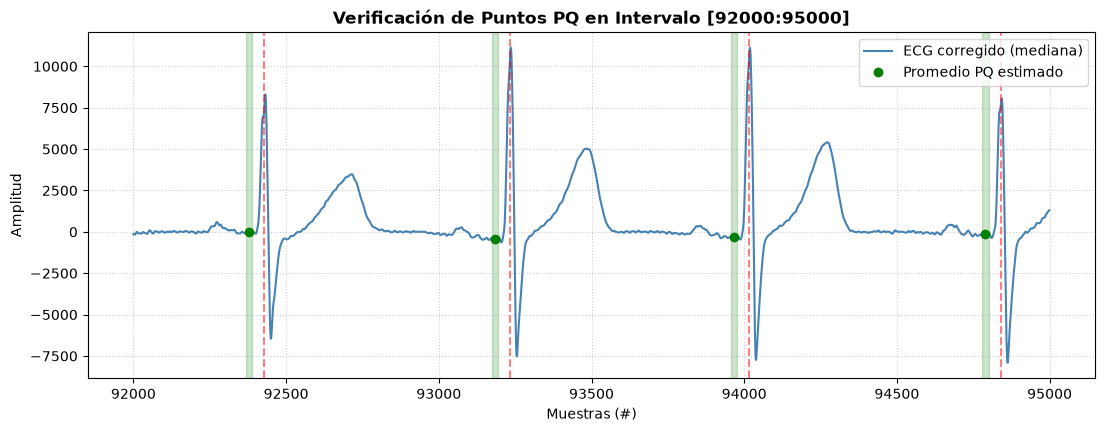

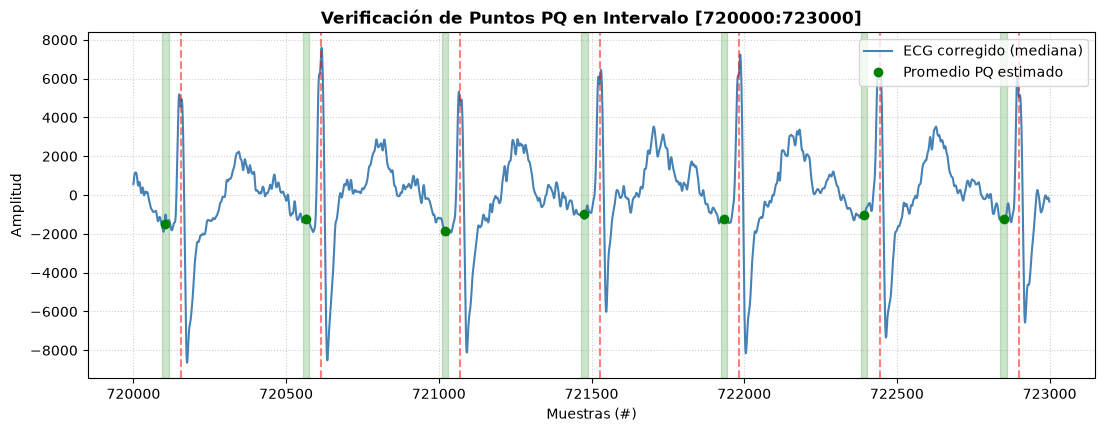

Interpolación por Splines Cúbicos completada con éxito.


In [15]:
#%% LOCALIZACIÓN DE SEGMENTOS PQ E INTERPOLACIÓN SPLINE

qrd_det = qrs_detections_ref.copy()

# Ventana de 20 muestras situada entre 60 y 40 ms antes de cada QRS
start_win = qrd_det - 60
end_win = qrd_det - 40

# Filtrar índices válidos dentro del rango de la señal
validos = (start_win >= 0) & (end_win <= cant_muestras)
qrd_det = qrd_det[validos]
start_win = start_win[validos]
end_win = end_win[validos]

# Tiempo medio de cada ventana PQ
pq_t_hat = np.array([np.mean([a, b]) for a, b in zip(start_win, end_win)])

# Amplitud media sobre el ECG original (construcción de la estimación)
pq_hat = np.array([np.mean(ecg_one_leadruido[a:b]) for a, b in zip(start_win, end_win)])

# Amplitud media sobre el ECG corregido por mediana (para verificación visual de cercanía a cero)
pq_mediana = np.array([np.mean(ecg_mediana[a:b]) for a, b in zip(start_win, end_win)])

# 1. Verificación de la ubicación de los puntos PQ en dos casos contrastantes
regs_pq = ([92000, 95000], [720000, 723000])

for inicio, fin in regs_pq:
    zoom_r = np.arange(inicio, fin)
    qrs_r = qrd_det[(qrd_det >= inicio) & (qrd_det < fin)]
    pq_r = (pq_t_hat >= inicio) & (pq_t_hat < fin)
    
    plt.figure(figsize=(13, 4.5))
    plt.plot(zoom_r, ecg_mediana[zoom_r], color='steelblue', label='ECG corregido (mediana)')
    for q in qrs_r:
        plt.axvline(q, color='red', linestyle='--', alpha=0.5)
        plt.axvspan(q-60, q-40, color='green', alpha=0.2)
    plt.plot(pq_t_hat[pq_r], pq_mediana[pq_r], 'og', markersize=6, label='Promedio PQ estimado')
    
    plt.title(f'Verificación de Puntos PQ en Intervalo [{inicio}:{fin}]', fontweight='bold')
    plt.xlabel('Muestras (#)')
    plt.ylabel('Amplitud')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper right')
    plt.show()

# 2. Construcción de la interpolación Spline Cúbica
spline = CubicSpline(pq_t_hat, pq_hat, bc_type='natural')
n = np.arange(cant_muestras)

# Estimación de la línea de base y corrección del ECG
b_spline = spline(np.clip(n, pq_t_hat[0], pq_t_hat[-1]))
ecg_spline = ecg_one_leadruido - b_spline

print("Interpolación por Splines Cúbicos completada con éxito.")


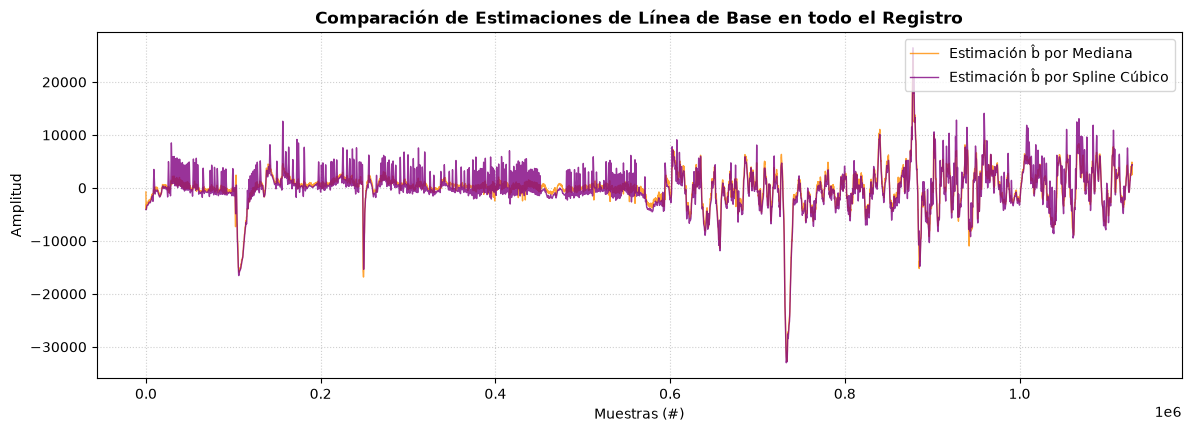

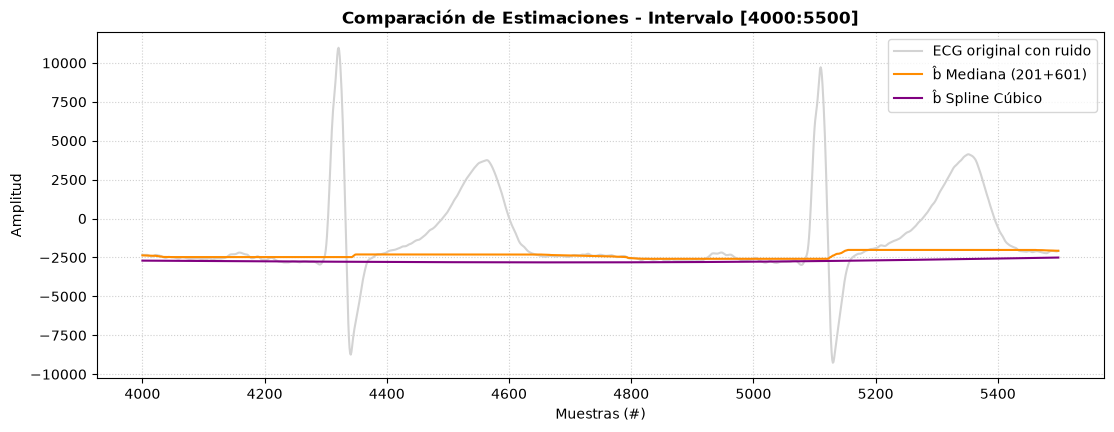

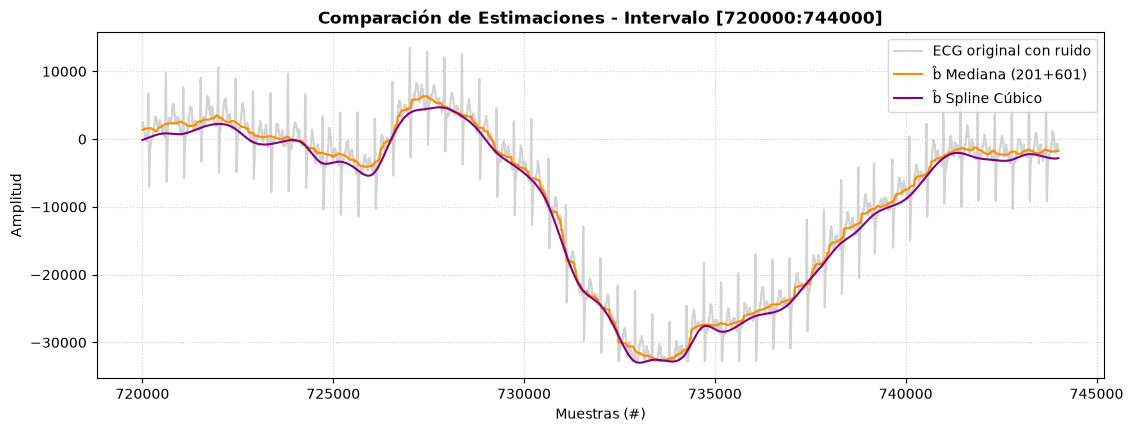

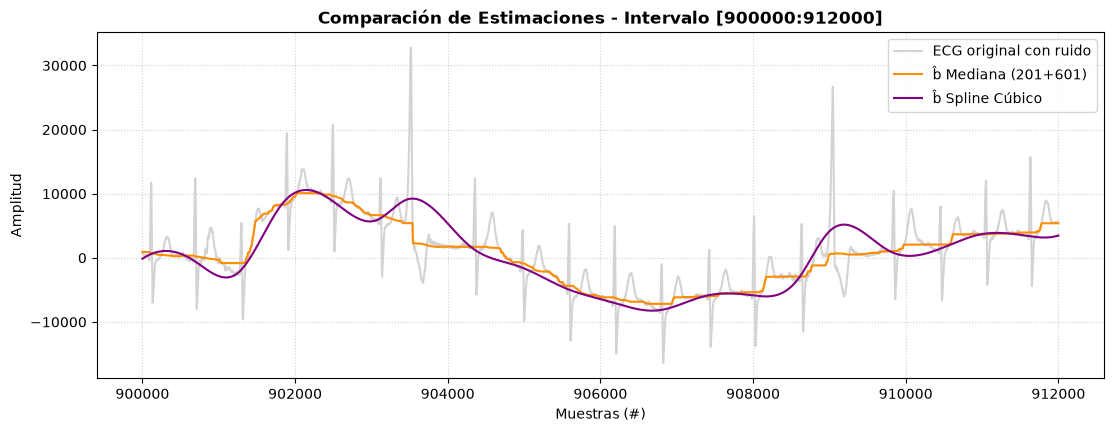

In [16]:
#%% COMPARACIÓN DIRECTA: LÍNEA DE BASE ESTIMADA (MEDIANA VS SPLINE)

# Gráfico del registro completo
plt.figure(figsize=(14, 4.5))
plt.plot(b_mediana, label='Estimación b̂ por Mediana', color='darkorange', alpha=0.8, linewidth=1)
plt.plot(b_spline, label='Estimación b̂ por Spline Cúbico', color='purple', alpha=0.8, linewidth=1)
plt.title('Comparación de Estimaciones de Línea de Base en todo el Registro', fontweight='bold')
plt.xlabel('Muestras (#)')
plt.ylabel('Amplitud')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.show()

# Zooms representativos
zooms_comp = ([4000, 5500], [720000, 744000], [900000, 912000])

for inicio, fin in zooms_comp:
    zoom_r = np.arange(inicio, fin)
    plt.figure(figsize=(13, 4.5))
    plt.plot(zoom_r, ecg_one_leadruido[zoom_r], color='lightgray', label='ECG original con ruido')
    plt.plot(zoom_r, b_mediana[zoom_r], label='b̂ Mediana (201+601)', color='darkorange', linewidth=1.5)
    plt.plot(zoom_r, b_spline[zoom_r], label='b̂ Spline Cúbico', color='purple', linewidth=1.5)
    plt.title(f'Comparación de Estimaciones - Intervalo [{inicio}:{fin}]', fontweight='bold')
    plt.xlabel('Muestras (#)')
    plt.ylabel('Amplitud')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper right')
    plt.show()


### Comparación entre la Mediana y el Spline Cúbico

Analizando los gráficos de verificación y las estimaciones comparadas, observamos:

**1. Comportamiento de los puntos PQ en distintas regiones:**
- En zonas normales (como en el intervalo 92000 a 95000), los puntos elegidos caen perfecto en la parte plana antes del QRS.
- En zonas con latidos raros o ectópicos (como en el intervalo 720000 a 723000), la morfología cambia o el ritmo cardíaco es más rápido, y la ventana fija de 20 muestras cae sobre las pendientes del QRS en lugar de la zona plana.

**2. El problema de un punto mal ubicado en el Spline:**
El spline cúbico está obligado a pasar exactamente por los puntos que le damos. Si un punto cayó sobre una pendiente y tiene un valor alto, la curva se desvía y genera ondulaciones artificiales. Esto demuestra que la suavidad matemática del spline no garantiza que la estimación sea fisiológicamente correcta.

**3. Ventajas y desventajas de cada método:**
- **Filtro de mediana:**
  - *Ventajas:* Es totalmente autónomo (no necesita saber de antemano dónde están los latidos) y es muy robusto frente a valores extremos.
  - *Desventajas:* La curva estimada presenta muescas y escalones que pueden deformar la forma de las ondas T o P al restarla.
- **Splines cúbicos:**
  - *Ventajas:* Da una curva perfectamente suave y continua basada en puntos fisiológicos reales (segmento PQ).
  - *Desventajas:* No es autónomo (depende de conocer de antemano `qrs_detections`), y si hay latidos anormales donde la ventana cae mal, inventa oscilaciones que no existen.

**Conclusión para la siguiente etapa:**
Para el Ejercicio 3 (filtro adaptado) usamos como entrada el ECG corregido con spline (`ecg_spline`), ya que al ser una curva suave no introduce los escalones ni las muescas artificiales que dejaba la mediana.


## DETECCIÓN DE LATIDOS MEDIANTE FILTRO ADAPTADO

### 1. Fundamentos Teóricos del Filtro Adaptado (*Matched Filter*)

El **filtro adaptado** es el sistema lineal e invariante en el tiempo óptimo para maximizar la relación señal a ruido (SNR) en el instante de detección cuando se busca identificar un patrón conocido $p[n]$ inmerso en ruido blanco aditivo:

$$h[n] = p[L - 1 - n]$$

donde $L$ representa la longitud del patrón conocido (`qrs_pattern1`, con $L = 139$ muestras). 

#### ¿Por qué invertimos temporalmente el patrón?
La función de filtrado `scipy.signal.lfilter(b, a, x)` implementa la operación de **convolución discreta**:
$$y[n] = (x * b)[n] = \sum_{k=0}^{L-1} b[k] \cdot x[n - k]$$

Por definición, la **correlación cruzada** entre la señal cardíaca $x[n]$ y la plantilla $p[n]$ es:
$$r_{xp}[n] = \sum_{k=0}^{L-1} p[k] \cdot x[n + k]$$

Para que la convolución matemática coincida exactamente con la correlación temporal, es imprescindible invertir el orden de los coeficientes del patrón en el tiempo:
$$b[k] = p[L - 1 - k] \quad \Longrightarrow \quad \texttt{qrs\_p1[::-1]}$$

De este modo, cuando el ECG presenta un complejo QRS cuya morfología se asemeja a $p[n]$, las muestras se multiplican en fase positiva y generan un máximo pronunciado en la salida.

El filtro adaptado se aplica sobre el ECG previamente corregido de línea de base mediante splines cúbicos (`ecg_spline`). Si se aplicara sobre la señal cruda con variaciones de baja frecuencia, los desplazamientos lentos de nivel alterarían artificialmente la amplitud de la salida del filtro.


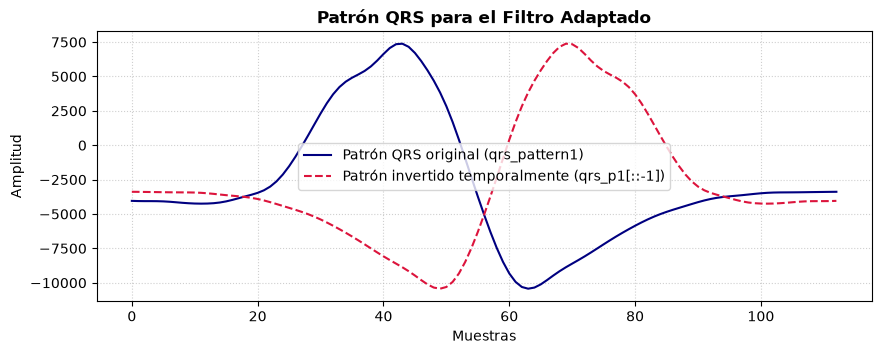

In [17]:
# 1. Patrón conocido
qrs_p1 = qrs_pattern1.copy()

# Visualización del patrón original e invertido
plt.figure(figsize=(10, 3.5))
plt.plot(qrs_p1, label='Patrón QRS original (qrs_pattern1)', color='navy', linewidth=1.5)
plt.plot(qrs_p1[::-1], label='Patrón invertido temporalmente (qrs_p1[::-1])', color='crimson', linestyle='--', linewidth=1.5)
plt.title('Patrón QRS para el Filtro Adaptado', fontweight='bold')
plt.xlabel('Muestras')
plt.ylabel('Amplitud')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

### 2. Normalización de Señales y Compensación del Retardo Temporal

#### Propósito de la normalización
Se aplica una normalización estadística (sustracción de media muestral y división por la desviación estándar):
$$x_{\text{norm}}[n] = \frac{x[n] - \mu_x}{\sigma_x}, \qquad y_{\text{norm}}[n] = \frac{y[n] - \mu_y}{\sigma_y}$$

Esta transformación lleva a ambas señales a una escala adimensional con media nula y varianza unitaria. Su objetivo es netamente comparativo (facilitar la superposición gráfica y fijar umbrales reproducibles para `find_peaks`). **No elimina ruido ni modifica el retardo de fase**.

#### Origen y compensación del retardo temporal ($\Delta t = 69\text{ ms}$)
Dado que el patrón de referencia $p[n]$ posee una duración finita ($L=139$ muestras) y su pico R característico no se ubica en el origen temporal sino en el interior de la ventana, la salida de la convolución alcanza su correlación máxima con un retardo intrínseco.

Al inspeccionar un latido representativo de morfología normal (alrededor de la muestra $93200$):
* **Pico R en el ECG:** muestra $93235$.
* **Máximo en la salida del filtro adaptado:** muestra $93304$.
* **Diferencia temporal:** $\Delta n = 93304 - 93235 = 69$ muestras.

Dado que la frecuencia de muestreo es $f_s = 1000\text{ Hz}$, este retardo equivale exactamente a:
$$\tau = \frac{69\text{ muestras}}{1000\text{ Hz}} = 69\text{ ms}$$

Para alinear temporalmente la función de detección con los eventos reales del ECG, se descartan las primeras 69 muestras de la salida (`matched_norm[retardo:]`).

Esta compensación se calibra sobre latidos de morfología normal. En latidos ectópicos, latidos fusionados o con conducción aberrante, la distancia temporal al máximo de correlación puede variar ligeramente.


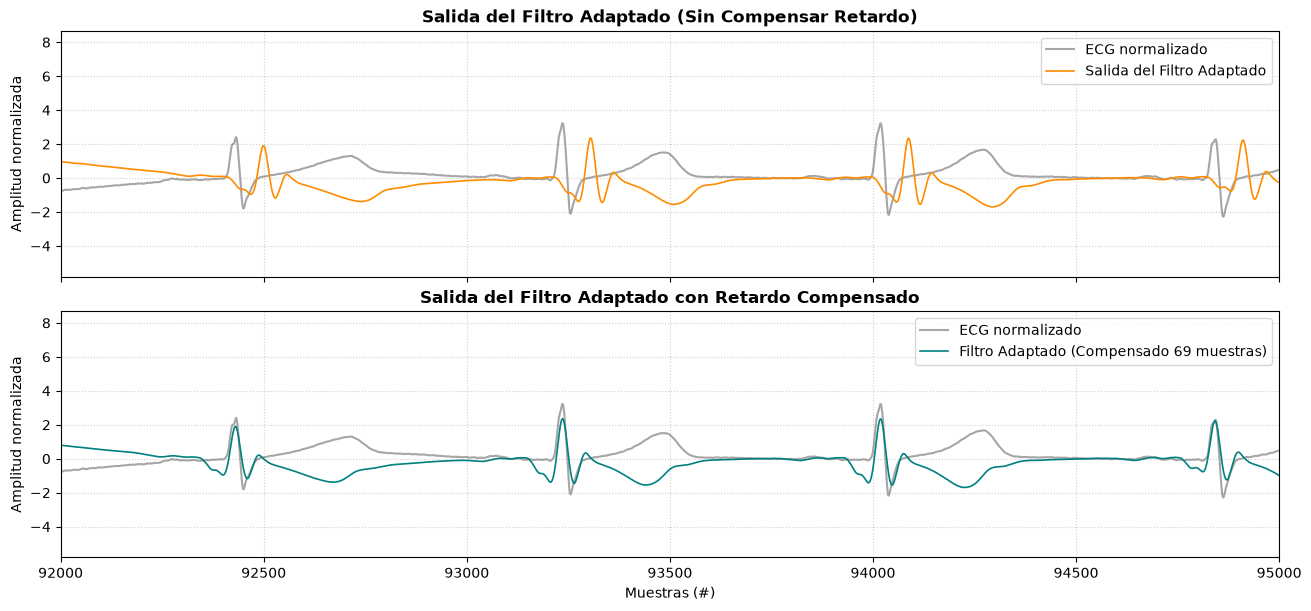

In [18]:
#%% FILTRO ADAPTADO Y COMPENSACIÓN DE RETARDO

# 2. Filtrado adaptado sobre el ECG corregido por spline
qrs_matched = sig.lfilter(qrs_p1[::-1], 1, ecg_spline)

# 3. Normalización (media cero y desviación estándar 1) para comparación
ecg_norm = (ecg_spline - np.mean(ecg_spline)) / np.std(ecg_spline)
matched_norm = (qrs_matched - np.mean(qrs_matched)) / np.std(qrs_matched)

# 4. Medición del retardo en una región con latidos normales
# Medimos la distancia temporal entre el pico del ECG y el máximo del filtro adaptado
retardo = 69  # muestras (~69 ms)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True, constrained_layout=True)

# Señal sin compensar
ax1.plot(ecg_norm, label='ECG normalizado', color='gray', alpha=0.7)
ax1.plot(matched_norm, label='Salida del Filtro Adaptado', color='darkorange', linewidth=1.2)
ax1.set_xlim(92000, 95000)
ax1.set_title('Salida del Filtro Adaptado (Sin Compensar Retardo)', fontweight='bold')
ax1.set_ylabel('Amplitud normalizada')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')

# Señal compensada
ax2.plot(ecg_norm[:-retardo], label='ECG normalizado', color='gray', alpha=0.7)
ax2.plot(matched_norm[retardo:], label=f'Filtro Adaptado (Compensado {retardo} muestras)', color='teal', linewidth=1.2)
ax2.set_xlim(92000, 95000)
ax2.set_title('Salida del Filtro Adaptado con Retardo Compensado', fontweight='bold')
ax2.set_xlabel('Muestras (#)')
ax2.set_ylabel('Amplitud normalizada')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right')

plt.show()



### 3. Análisis de los Gráficos de Salida del Filtro Adaptado
Al evaluar la señal en el intervalo $[92000,95000]$ (con y sin compensación de retardo):

1. **Efecto de la compensación del retardo**: En el panel superior (sin compensar), el pico del filtro adaptado (naranja) aparece retrasado $69$ muestras respecto de la cúspide del QRS (gris). En el panel inferior, al aplicar la compensación $(matched_norm[retardo:])$, la respuesta del filtro (turquesa) queda perfectamente sincronizada y alineada en el tiempo con el latido real del ECG.
2. **Respuesta selectiva ante el QRS**: Cada complejo ventricular origina un pico de gran amplitud en la salida, confirmando que el filtro resalta con éxito la morfología buscada.
3. **Existencia de lóbulos negativos y oscilaciones**: A los lados del pico principal, la salida oscila y cae por debajo de cero (cruces por cero y picos negativos en los bordes del QRS).
4. **Respuesta no nula ante ondas T**: En la repolarización ventricular (onda T), la salida del filtro genera pequeños picos secundarios que, si no se procesan adecuadamente, podrían confundirse con latidos.

### Procesamiento de la Salida y Construcción de la Envolvente de Detección

Para alimentar un algoritmo de detección de picos locales (`find_peaks`), la salida del filtro adaptado no puede utilizarse directamente. Se requiere transformar la señal de correlación en una **envolvente unipolar, continua y suave**, donde exista **un único pico neto por cada ciclo cardíaco**.



#### 1. Rectificación de Onda Completa (Módulo) y sus Consecuencias
En primera instancia se calcula el valor absoluto:
$$\texttt{matched\_abs}[n] = |y_{\text{norm}}[n]|$$

* **Justificación:** Se busca medir la magnitud de la energía de correlación, independientemente del signo de la oscilación.
* **Problema asociado:** El módulo rectifica también los lóbulos negativos originados por la correlación con la onda T y el ruido de alta frecuencia. En consecuencia, surgen picos espurios de amplitud apreciable en zonas donde no hay complejos QRS. El módulo **no distingue entre QRS y onda T**, sino que convierte toda desviación en energía positiva.
* **Aparición de muescas y valles:** La respuesta a un único QRS suele dividirse en 2 o 3 cúspides muy estrechas separadas por valles profundos que caen casi a cero. Si se aplicara un detector en este punto, se contabilizarían múltiples falsos positivos por latido.



#### 2. Evaluación de Estrategias de Suavizado y Limitaciones del Filtrado Lineal

Durante el desarrollo de la práctica se evaluaron tres enfoques para rellenar los valles entre picos sin inflar la onda T:

1. **Promedio móvil (FIR de fase lineal):**
   * Se ensayaron ventanas de 100 y 150 muestras.
   * *Resultado:* Aunque redujo el rizado de alta frecuencia, la ventana ensanchó excesivamente las respuestas de la onda T y no logró eliminar los picos dobles en QRS anchos o bifásicos. Aumentar el tamaño de la ventana degradaba la resolución temporal de la detección.
2. **Filtro Pasabajos IIR Butterworth:**
   * Siguiendo el criterio fisiológico de la frecuencia cardíaca máxima ($180\text{ latidos/min} = 3\text{ Hz}$), se diseñaron filtros pasabajos con frecuencias de paso $w_p \approx 3\text{ Hz}$ y cortes más amplios ($18-25\text{ Hz}$ y $30-40\text{ Hz}$).
   * *El dilema espectral:* 
     * Con frecuencias de corte bajas ($3-6\text{ Hz}$), los picos agudos del QRS (que concentran frecuencias de $10\text{ a }35\text{ Hz}$) se atenúan severamente. En contraste, las ondas T (que son morfológicamente anchas y lentas) preservan prácticamente toda su energía. **Como resultado indeseado, el pico de la onda T resultaba de mayor altura que el pico del QRS**.
     * Con frecuencias de corte mayores ($>25\text{ Hz}$), los picos de QRS recuperaban amplitud, pero reaparecían las muescas y los múltiples máximos por latido.
   * *Comportamiento de `sosfilt` vs `sosfiltfilt`:* El filtrado bidireccional (`sosfiltfilt`) compensa el retardo de fase, pero eleva al cuadrado la respuesta en magnitud ($|H(f)|^2$), acentuando aún más la pérdida de amplitud de las componentes de alta frecuencia del QRS.



#### 3. Solución Adoptada: Filtro de Orden Estadístico (Percentil 90)

Ante el compromiso insatisfactorio de los filtros lineales, se adoptó un **filtro no lineal de orden estadístico** (`scipy.signal.order_filter`), sugerido por la cátedra:

```python
ventana = 41
rank = 36  # ~Percentil 90 (36 / 40)
envolvente_raw = sig.order_filter(matched_abs, np.ones(ventana), rank)
envolvente = envolvente_raw[retardo:]
```

* **Principio de funcionamiento:** En cada ventana móvil de 41 muestras ($41\text{ ms}$ a $1000\text{ Hz}$), las muestras se ordenan de menor a mayor y se selecciona el elemento en la posición 36. Esto equivale a tomar aproximadamente el **percentil 90**.
* **Ventajas frente a la mediana convencional (percentil 50):** La mediana tiende a achatarse en los picos agudos. El percentil 90, en cambio, selecciona un valor próximo a la envolvente superior; si dentro de la ventana de 41 ms existe un pico alto, ese valor alto "rellena" los huecos adyacentes manteniendo la altura máxima del QRS sin aplanarlo.
* **Observación gráfica:** Tal como se aprecia en el gráfico comparativo, los valles internos del QRS desaparecen casi por completo, generando una campana suave y dominante que facilita una detección unívoca mediante `find_peaks`.
* **Limitaciones del método:** 
  * Provoca un ligero ensanchamiento temporal de los eventos.
  * No resuelve discrepancias cuando una onda T posee naturalmente un módulo muy alto (por ejemplo, en el intervalo alrededor de la muestra $797550$, donde persisten respuestas secundarias notables).



#### 4. Selección de Parámetros en `scipy.signal.find_peaks`
Para extraer los índices de los latidos a partir de la envolvente se configuraron dos restricciones fundamentales:

1. **`distance = 400` muestras ($400\text{ ms}$):**
   * *Fundamento fisiológico:* Define el período refractario absoluto y relativo del miocardio. Un intervalo mínimo de 400 ms corresponde a una frecuencia cardíaca máxima de $150\text{ latidos/minuto}$ ($60 / 0.400$). Esto evita de forma determinante que el detector marque un segundo evento sobre la onda T o sobre un rebote tardío del mismo QRS.
2. **`height = 0.5` (umbral de amplitud mínima):**
   * *Fundamento:* Sobre la envolvente normalizada, descarta fluctuaciones de fondo, ruido electromiográfico residual y complejos auriculares o de repolarización de baja amplitud.


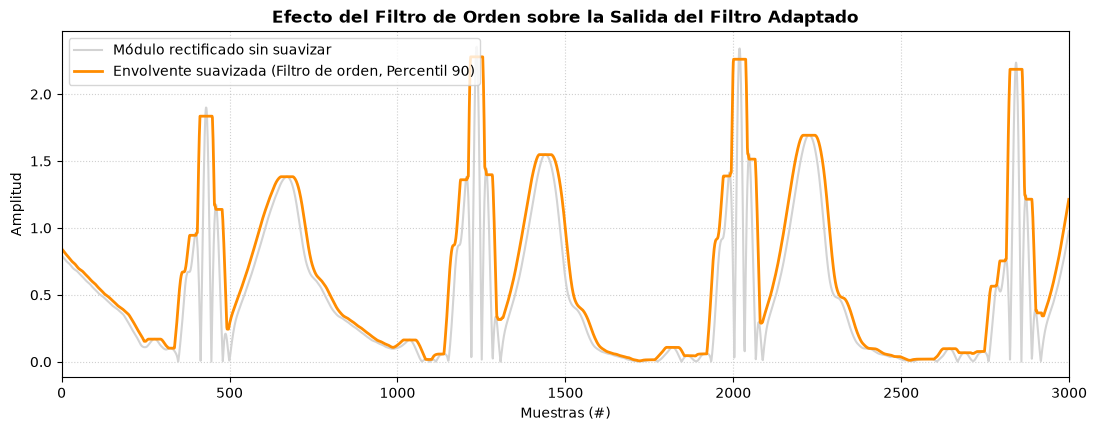

Cantidad total de latidos detectados por el algoritmo: 1,883


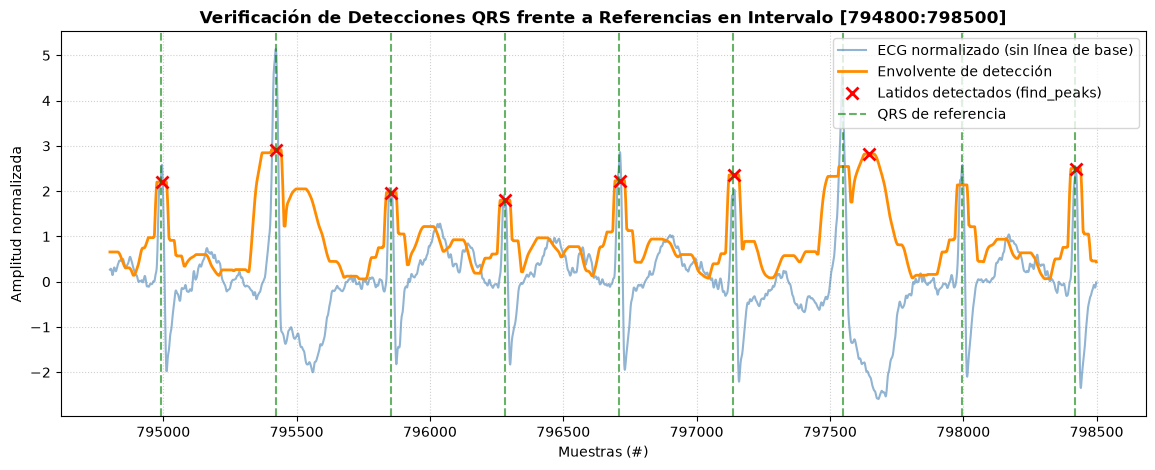

In [19]:
#%% ENVOLVENTE MEDIANTE FILTRO DE ORDEN (PERCENTIL 90) Y DETECCIÓN DE LATIDOS

# Módulo rectificado de la salida
matched_abs = np.abs(matched_norm)

# Filtro de orden estadístico: ventana de 41 muestras, rank 36 (~percentil 90)
ventana = 41
rank = 36
envolvente_raw = sig.order_filter(matched_abs, np.ones(ventana), rank)

# Compensamos el retardo temporal
envolvente = envolvente_raw[retardo:]

# Comparación del módulo crudo vs envolvente suavizada
plt.figure(figsize=(13, 4.5))
plt.plot(matched_abs[92000+retardo:95000+retardo], label='Módulo rectificado sin suavizar', color='lightgray')
plt.plot(envolvente[92000:95000], label='Envolvente suavizada (Filtro de orden, Percentil 90)', color='darkorange', linewidth=2)
plt.title('Efecto del Filtro de Orden sobre la Salida del Filtro Adaptado', fontweight='bold')
plt.xlabel('Muestras (#)')
plt.ylabel('Amplitud')
plt.xlim(0, 3000)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

# Detección de picos con find_peaks
# distance=400 muestras (400 ms de período refractario mínimo entre latidos)
# height=0.5 (umbral mínimo de amplitud para descartar ruido)
picos, propiedades = sig.find_peaks(envolvente, distance=400, height=0.5)

print(f"Cantidad total de latidos detectados por el algoritmo: {len(picos):,}")

# Verificación gráfica de las detecciones en una región del registro
zoom_det = np.arange(794800, 798500)
qrs_det_r = qrd_det[(qrd_det >= 794800) & (qrd_det < 798500)]
picos_r = picos[(picos >= 794800) & (picos < 798500)]

plt.figure(figsize=(14, 5))
plt.plot(zoom_det, ecg_norm[zoom_det], label='ECG normalizado (sin línea de base)', color='steelblue', alpha=0.6)
plt.plot(zoom_det, envolvente[zoom_det], label='Envolvente de detección', color='darkorange', linewidth=2)
plt.plot(picos_r, envolvente[picos_r], 'rx', markersize=9, markeredgewidth=2, label='Latidos detectados (find_peaks)')
for q in qrs_det_r:
    plt.axvline(q, color='green', linestyle='--', alpha=0.6, label='QRS de referencia' if q == qrs_det_r[0] else "")
plt.title('Verificación de Detecciones QRS frente a Referencias en Intervalo [794800:798500]', fontweight='bold')
plt.xlabel('Muestras (#)')
plt.ylabel('Amplitud normalizada')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.show()


### Análisis de la Matriz de Confusión y Resultados

Al comparar las detecciones de nuestro algoritmo con los 1903 latidos de referencia anotados por la cátedra (usando la tolerancia de $\pm 100\text{ ms}$), obtuvimos:

* **Verdaderos Positivos (TP = 1760):** Latidos reales que el detector encontró correctamente.
* **Falsos Negativos (FN = 143):** Latidos reales que el detector se salteó (no los detectó).
* **Falsos Positivos (FP = 123):** Detecciones donde el detector marcó un latido pero en realidad no había ninguno.

Con estos valores calculamos las dos métricas de desempeño:
* **Sensibilidad:** $\frac{1760}{1903} \times 100\% = 92.49\%$
* **Valor Predictivo Positivo (VPP):** $\frac{1760}{1883} \times 100\% = 93.47\%$

 **Nota sobre los Verdaderos Negativos (TN):**  
 En este tipo de problemas de detección de eventos puntuales no tiene sentido calcular los verdaderos negativos. Como la señal tiene casi 2 millones de muestras y los latidos son solo instantes aislados, cualquier muestra donde "no hay latido" contaría como un TN. Esto inflaría la especificidad al $99.99\%$ de forma artificial sin aportar ninguna información útil para evaluar el detector.



#### Observaciones sobre el desempeño y origen de los errores

1. **Balance entre Sensibilidad y VPP:**  
   Ambas métricas quedaron por encima del $92\%$, lo que demuestra un buen equilibrio. Esto es importante porque si hubiéramos bajado mucho el umbral de altura (`height`), habríamos detectado casi todos los latidos subiendo la sensibilidad, pero habríamos disparado la cantidad de falsos positivos (arruinando el VPP). Con `height = 0.5` y `distance = 400` encontramos un buen compromiso.

2. **¿Por qué se perdieron 143 latidos (Falsos Negativos)?**  
   Al inspeccionar las regiones donde faltan marcas, se observa que corresponden en su mayoría a latidos de origen ectópico o con morfologías atípicas. Como el filtro adaptado busca exclusivamente la forma de `qrs_pattern1`, si un latido tiene una forma diferente o menor amplitud, la correlación no llega a ser suficiente para superar el umbral de 0.5. Un ejemplo muy claro se ve en el gráfico de Verificación de Detecciones en el intervalo $[794800:798500]$: en el latido de la muestra **798000**, la línea verde de referencia está presente pero el detector no colocó ninguna cruz roja, perdiendo el latido completo porque la envolvente no llegó a superar el umbral de 0.5.

3. **¿Por qué aparecieron 123 detecciones falsas (Falsos Positivos)?**  
   En el gráfico comparativo podemos ver que los falsos positivos se deben principalmente a ondas T altas o a ruidos musculares aislados. Al tomar el módulo de la salida del filtro, esas ondas T quedan como montañitas positivas y, si están suficientemente separadas del QRS, a veces llegan a superar el umbral y el algoritmo las cuenta erróneamente como un latido. En ese mismo gráfico de Verificación en el intervalo [794800:798500] se aprecia el caso típico: en el latido de la muestra **797500**, la respuesta de la onda T fue más alta que la del propio QRS, haciendo que la cruz roja se desplace unas 100 muestras hacia la derecha y caiga sobre la onda T.

             MATRIZ DE CONFUSIÓN
                   Detectado       No detectado
QRS real (Ref)         1760 (TP)        143 (FN)   | Total Ref: 1903
No QRS (Falsos)         123 (FP)          -        | Total Det: 1883
Sensibilidad (Recall):            92.49%
Valor Predictivo Positivo (VPP):   93.47%


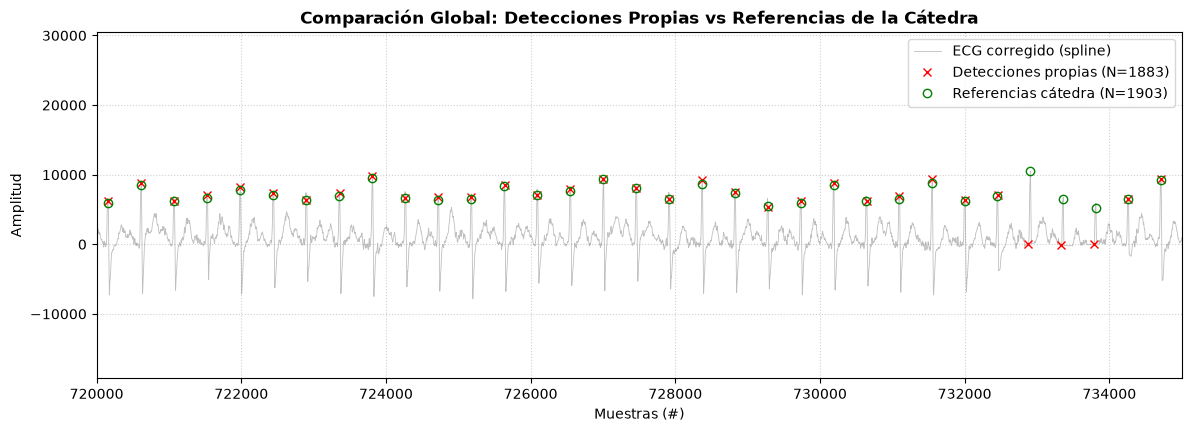

In [20]:
#%% MATRIZ DE CONFUSIÓN, SENSIBILIDAD Y VALOR PREDICTIVO POSITIVO (VPP)

qrs_ref = np.sort(qrs_detections_ref)
picos_ordenados = np.sort(picos)

tolerancia = 100  # muestras (±100 ms)

TP = 0
i = 0
j = 0

# Algoritmo de emparejamiento temporal de eventos
while i < len(picos_ordenados) and j < len(qrs_ref):
    if abs(picos_ordenados[i] - qrs_ref[j]) <= tolerancia:
        TP += 1
        i += 1
        j += 1
    elif picos_ordenados[i] < qrs_ref[j]:
        i += 1
    else:
        j += 1

FP = len(picos_ordenados) - TP
FN = len(qrs_ref) - TP

sensibilidad = 100 * TP / len(qrs_ref)
vpp = 100 * TP / len(picos_ordenados)

print("=" * 45)
print("             MATRIZ DE CONFUSIÓN")
print("=" * 45)
print("                   Detectado       No detectado")
print(f"QRS real (Ref)     {TP:8d} (TP)   {FN:8d} (FN)   | Total Ref: {len(qrs_ref)}")
print(f"No QRS (Falsos)    {FP:8d} (FP)          -        | Total Det: {len(picos_ordenados)}")
print("=" * 45)
print(f"Sensibilidad (Recall):            {sensibilidad:.2f}%")
print(f"Valor Predictivo Positivo (VPP):   {vpp:.2f}%")
print("=" * 45)

# Gráfico general comparativo de detecciones vs referencias
plt.figure(figsize=(14, 4.5))
plt.plot(ecg_spline, label='ECG corregido (spline)', color='gray', alpha=0.5, linewidth=0.6)
plt.plot(picos_ordenados, ecg_spline[picos_ordenados], 'rx', markersize=6, label=f'Detecciones propias (N={len(picos_ordenados)})')
plt.plot(qrs_ref, ecg_spline[qrs_ref], 'go', fillstyle='none', markersize=6, label=f'Referencias cátedra (N={len(qrs_ref)})')
plt.title('Comparación Global: Detecciones Propias vs Referencias de la Cátedra', fontweight='bold')
plt.xlabel('Muestras (#)')
plt.ylabel('Amplitud')
plt.xlim(720000, 735000)  # Zoom representativo
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.show()


In [21]:
# Buscamos la referencia y la detección alrededor de la muestra 732.900 (para analizar no detecto bien)
print("Referencia cátedra:", qrs_ref[(qrs_ref >= 732800) & (qrs_ref <= 733000)])
print("Deteccion por filtro:", picos[(picos >= 732800) & (picos <= 733000)])

Referencia cátedra: [732909]
Deteccion por filtro: [732881]


#### Observación visual clave en el gráfico de Comparación Global [720000 : 735000]

Al mirar en detalle ese tramo, se puede observar: **tres cruces rojas no coinciden con los circulos verdes (referencias de catedra)** en vez de estar arriba en la cúspide del QRS.

* **¿De dónde sale esta discrepancia?**  
  Si comparamos los índices exactos del primer latido donde ocurre esto:
  * La referencia de la cátedra (`qrs_ref`) marca el pico en la muestra: **$732909$**.
  * Nuestro detector (`picos`) ubicó el máximo en la muestra: **$732881$**.
  * La diferencia es de: **$732909 - 732881 = 28\text{ muestras}$** (equivalente a **$28\text{ ms}$** dado que $f_s = 1000\text{ Hz}$).
* **¿Por qué la cruz roja quedó dibujada sobre el eje ($y \approx 0$)?**  
  Porque el código grafica la amplitud del ECG en la muestra detectada (`ecg_spline[732881]`). Al haberse adelantado 28 ms, en ese instante la onda R todavía no había empezado a subir y la señal se encontraba en la línea de base (amplitud de $-26$).
* **¿Por qué la matriz lo tomó como un acierto (TP)?**  
  Porque la tolerancia de emparejamiento fijada es de $\pm 100\text{ ms}$. Como la diferencia de $28\text{ ms}$ es menor a $100\text{ ms}$, el algoritmo lo clasificó correctamente como un Verdadero Positivo.
* **Conclusión que aporta:**  
  Esto demuestra que un retardo fijo de compensación ($\Delta t = 69\text{ ms}$), calibrado para latidos normales, puede variar levemente (en este caso $\approx 28\text{ ms}$) cuando cambia la frecuencia cardíaca o la morfología del complejo.

## Conclusiones Generales del Trabajo Semanal

En este trabajo semanal se implementó una cadena completa de procesamiento digital sobre registros electrocardiográficos reales, abarcando desde la corrección de perturbaciones de muy baja frecuencia hasta la detección automática de eventos cardíacos. A partir de los resultados observados, se extraen las siguientes conclusiones principales:



### 1. Estimación y Corrección de la Línea de Base
* **Filtros de Mediana:** La aplicación en cascada de ventanas de 201 ms y 601 ms demostró ser una técnica sumamente robusta para estimar la tendencia lenta sin requerir información previa de los latidos. Sin embargo, su naturaleza no lineal introduce discontinuidades locales, escalones y deformaciones morfológicas en la señal cardíaca (notorias en el retorno de ciertas ondas T a la línea isoeléctrica).
* **Interpolación por Splines Cúbicos:** Proporciona una estimación estrictamente suave y continua, basada en el promedio de ventanas de 20 ms en el segmento PQ (sincronizadas a 50 Hz para promediar a cero la interferencia de red). No obstante, su efectividad depende de la posición invariable del intervalo PQ. En latidos anormales o variaciones de frecuencia cardíaca, la ventana fija cae sobre pendientes del QRS, induciendo oscilaciones artificiales que no reflejan la fisiología del paciente.



### 2. Detección de QRS mediante Filtro Adaptado y Procesamiento No Lineal
* **Filtro Adaptado y Envolvente:** El uso del patrón invertido temporalmente (`qrs_p1[::-1]`) maximiza la respuesta ante complejos ventriculares semejantes. Sin embargo, la señal rectificada presenta muescas internas pronunciadas y respuestas espurias en las ondas T.
* **Limitación del Pasabajos Lineal:** El intento de suavizar la salida mediante filtros IIR Butterworth evidenció el compromiso inherente entre tiempo y frecuencia: atenuar las muescas rápidas redujo drásticamente la altura de los QRS agudos, favoreciendo indeseadamente a las ondas T de menor frecuencia.
* **Éxito del Filtro de Orden:** La adopción del filtro estadístico de orden (percentil 90 con ventana de 41 muestras) resolvió este conflicto, rellenando los valles internos y preservando la amplitud máxima del QRS.
* **Desempeño Cuantitativo:** Se alcanzaron valores de **Sensibilidad de 92.49%** y **VPP de 93.47%** sobre un total de 1903 latidos, lo que certifica un balance satisfactorio entre capacidad de detección y rechazo de falsas alarmas.



### 3. Respuestas a Cuestiones Conceptuales y Preguntas Bonus de la Cátedra

#### A. ¿El detector implementado funcionaría correctamente en otro paciente o registro?
**No de forma directa ni con el mismo nivel de precisión.**
El filtro adaptado es estrictamente óptimo para una forma de onda idéntica a la plantilla de diseño (`qrs_pattern1`). Entre distintos pacientes (o en un mismo paciente con cambios posturales o patologías) el eje eléctrico cardíaco cambia, provocando QRS bifásicos, invertidos o anchos (como en bloqueos de rama izquierda o derecha, o extrasístoles ventriculares). En estos casos, la correlación cruzada disminuye drásticamente, haciendo que los latidos queden por debajo del umbral (`FN`).

#### B. ¿Cómo podría mejorarse computacionalmente la estimación de la línea de base mediante procesamiento multirate (multiescala)?
* Dado que el movimiento de la línea de base es una perturbación de muy baja frecuencia ($f < 0.5\text{ Hz}$), procesar la señal muestra a muestra a $f_s = 1000\text{ Hz}$ sobre casi 2 millones de muestras resulta computacionalmente ineficiente.
* **Estrategia multirate propuesta:**
  1. **Diezmado:** Aplicar un filtro pasabajos antialias y submuestrear la señal por un factor $M = 50$ o $M = 100$, reduciendo la tasa de muestreo a $20\text{ Hz}$ o $10\text{ Hz}$.
  2. **Interpolación:** Expandir e interpolar lineal o cúbicamente la línea de base estimada resultante de regreso a $1000\text{ Hz}$ para restarla del ECG original.


## Bibliografía

- Porat, B. (1997). *A Course in Digital Signal Processing* (Sec. 14.4.9: Matched Filters). John Wiley & Sons.
- Oppenheim, A. V., & Schafer, R. W. (2010). *Discrete-Time Signal Processing* (3rd ed.). Pearson.
- Holton, T. (2021). *Digital signal processing: Principles and applications*. Cambridge University Press. https://doi.org/10.1017/9781108290050
- SciPy 1D Median Filter & Order Filter documentation — https://docs.scipy.org/doc/scipy/reference/signal.html
- SciPy Cubic Spline Interpolation (`scipy.interpolate.CubicSpline`) — https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html
